In [32]:
import pandas as pd

df = pd.read_csv("data/titanic_data.csv")
df.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [33]:
df.shape

(891, 15)

In [34]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [35]:
# Check for total number of missing values in each column
df.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [36]:
df.groupby("sex")["survived"].mean()

sex
female    0.742038
male      0.188908
Name: survived, dtype: float64

Did this passenger survive with these Inputs given: Sex, age, class, fare, where they boarded ?

In [37]:
import matplotlib.pyplot as plt
import seaborn as sns

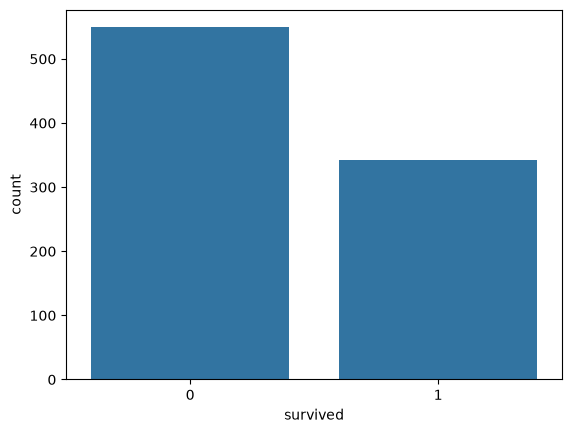

In [38]:
# # Target balance
sns.countplot(x="survived", data=df)
plt.show()

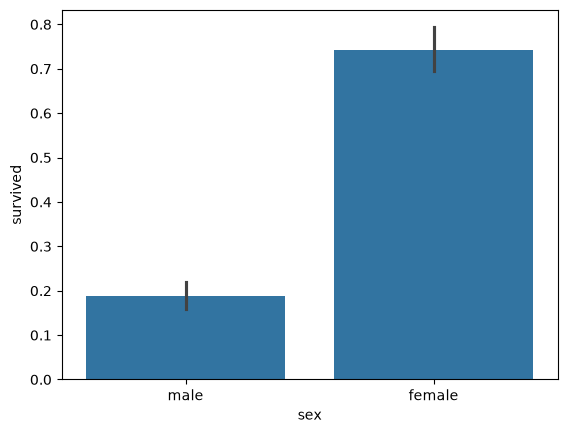

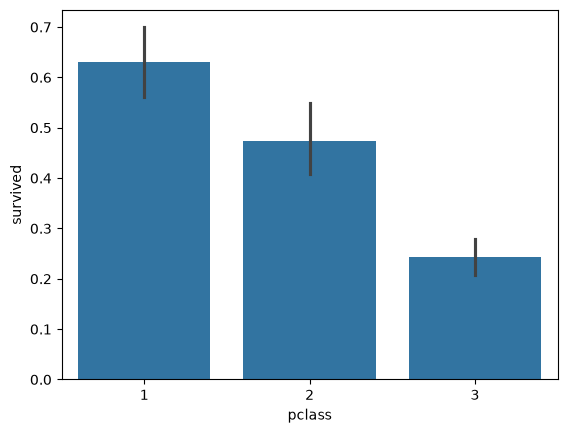

In [39]:
# 2. Survival rate by sex and by class
sns.barplot(x="sex", y="survived", data=df)
plt.show()
sns.barplot(x="pclass", y="survived", data=df)
plt.show()

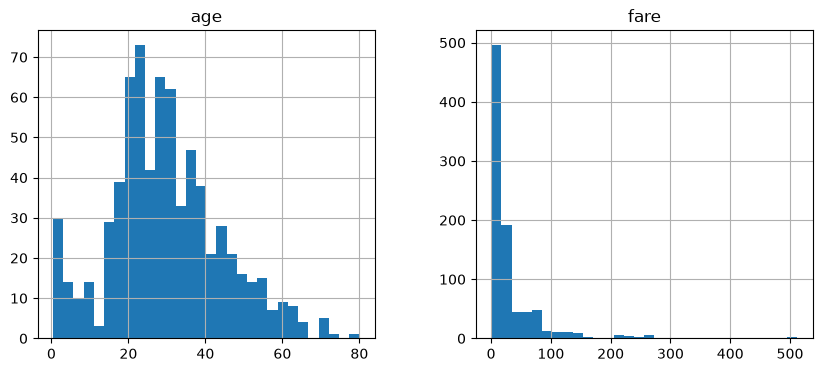

In [40]:
# 3. Distributions of the numeric inputs
df[["age", "fare"]].hist(bins=30, figsize=(10, 4))
plt.show()

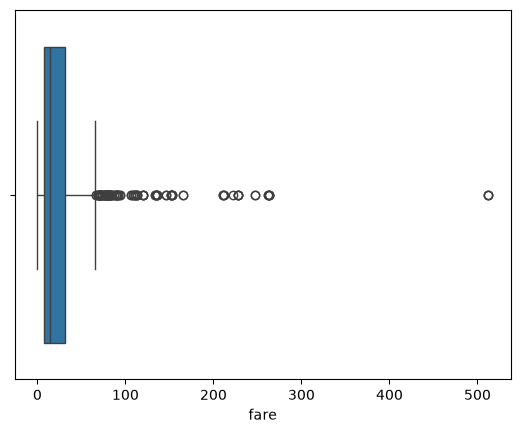

In [41]:
# 4. Outliers
sns.boxplot(x="fare", data=df)
plt.show()

In [42]:
cols = ["sex", "age", "pclass", "fare", "embarked", "survived"]
data = df[cols].dropna()
print(df.shape, "->", data.shape)

(891, 15) -> (712, 6)


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
import numpy as np

In [57]:
X = data.drop(columns="survived")
y = data["survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)


In [45]:
# ColumnTransformer applies a different transformation to different columns, then joins the results into one array.
# Each tuple has three parts: (name, transformer, columns)
# remainder: what to do with columns not listed. The default "drop" throws them away. "passthrough" keeps them unchanged
pre = ColumnTransformer([
    ("num", StandardScaler(), ["age", "fare"]),
    ("cat", OneHotEncoder(drop="first"), ["sex", "embarked"])
], remainder="passthrough")

In [46]:
"""
The two stages
fit = learn the numbers needed for the transformation. Nothing in your data changes.
transform = use those learned numbers to change the data.
Tiny example with StandardScaler

Say the training ages are [10, 20, 30].

fit calculates and stores:

mean = 20
standard deviation ≈ 8.16
"""
X_train_p = pre.fit_transform(X_train) # learn from train, then transform train
X_test_p = pre.transform(X_test) # reuse what was learned, transform test

In [47]:
print(X_train_p.shape, X_test_p.shape)
print(np.isnan(X_train_p).sum())

(569, 6) (143, 6)
0


LOGISTIC REGRESSION

In [48]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)
model.fit(X_train_p, y_train)

,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use i

In [49]:
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

y_pred = model.predict(X_test_p)

print(accuracy_score(y_test, y_pred))
print(confusion_matrix(y_test, y_pred))
print(classification_report(y_test, y_pred))

0.7762237762237763
[[70 15]
 [17 41]]
              precision    recall  f1-score   support

           0       0.80      0.82      0.81        85
           1       0.73      0.71      0.72        58

    accuracy                           0.78       143
   macro avg       0.77      0.77      0.77       143
weighted avg       0.78      0.78      0.78       143



In [ ]:
feature_names = pre.get_feature_names_out()

# model.coef_[0] holds the coefficient the model learned for each of those columns.
# pd.Series(..., index=feature_names) pairs each coefficient with its name.
coefs = pd.Series(model.coef_[0], index=feature_names)

"""
Each number is a log-odds weight. Logistic regression computes:

log-odds of survival = b0 + b1·age + b2·fare + ...

Positive coefficient: a higher value of that feature raises the chance of survival.
Negative coefficient: a higher value lowers it.
Size: a larger absolute value means a stronger effect. Comparing sizes is fair for age and fare because they’re scaled to the same units.
Zero or near zero: little effect.
"""
print(coefs.sort_values())

cat__sex_male       -2.402711
remainder__pclass   -1.254894
cat__embarked_S     -0.521943
num__age            -0.520294
cat__embarked_Q     -0.410049
num__fare           -0.129385
dtype: float64


### CROSS VALIDATION EVALUATION

In [ ]:
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline

# pipeline = a sequence of steps. Each step is a tuple of (name, transformer/estimator). The last step must be an estimator (read more about this).
# In a Pipeline, all steps except the last must be transformers. When you call fit, it calls fit_transform on each transformer in order, 
# passing the output of one as the input to the next. The last step is an estimator, so it just calls fit on that.
pipe = Pipeline([("pre", pre), ("clf", LogisticRegression(max_iter=1000))])
# Here we are using this explicitly defined StratifiedKFold object to ensure that the folds are shuffled.
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# For a classifier, cv=5 already uses StratifiedKFold(n_splits=5) internally, so stratification is the same either way.
scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="accuracy")
print(scores.mean(), scores.std())

0.7978885266263003 0.03235716125357207
